# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Rayhan Alif Zahrandhika Rizqullah
- **Email:** rayhanalif5@gmail.com
- **ID Dicoding:** rayhan_alif_6Enz

---

## Menentukan Pertanyaan Bisnis

Tujuan analisis ini adalah untuk memahami bagaimana faktor operasional dan cuaca memengaruhi tingkat penggunaan layanan penyewaan sepeda harian. Dua pertanyaan utama yang akan dijawab meliputi:

1. **Pertanyaan 1:** Bagaimana perbandingan rata-rata penyewaan sepeda harian antara hari kerja (*workingday*) dan hari libur/akhir pekan pada setiap musim di tahun 2012?
2. **Pertanyaan 2:** Bagaimana pola sebaran jumlah penyewaan sepeda harian berdasarkan kelompok suhu udara (*temp_category*) pada rentang tahun 2011–2012?

## Import All Packages/Libraries

Mengimpor seluruh library yang dibutuhkan untuk pemrosesan data, manipulasi array, serta pembuatan grafik visualisasi.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

## Data Wrangling

Tahap ini mencakup pengumpulan data dari file CSV, pemeriksaan kualitas data untuk mendeteksi masalah (*missing values*, duplikat, dan ketidaksesuaian tipe data), serta pembersihan data.

### Gathering Data
Memuat dataset `day.csv` ke dalam DataFrame `day_df`.

In [11]:
# Gathering Data
day_df = pd.read_csv('day.csv')

# Menampilkan 5 baris pertama data
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Assessing Data
Mengecek struktur data, keterisian kolom, tingkat duplikasi, serta gambaran nilai statistik awal dari variabel-variabel yang ada.

In [12]:
# Assessing Data
print("=== Informasi Tipe Data ===")
print(day_df.info())

print("\n=== Jumlah Missing Values ===")
print(day_df.isna().sum())

print("\n=== Jumlah Data Duplikat ===")
print("Duplikasi:", day_df.duplicated().sum())

print("\n=== Ringkasan Statistik Deskriptif ===")
print(day_df.describe())

=== Informasi Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None

=== Jumlah Missing Values ===
instant       0
dteday       

### Cleaning Data
Berdasarkan hasil asesmen, tidak ditemukan data hilang maupun duplikat. Namun, ada beberapa perbaikan format agar analisis lebih intuitif:
1. Mengubah kolom `dteday` ke tipe `datetime`.
2. Melakukan *mapping* kode numerik pada kolom `season` dan `workingday` menjadi teks eksplisit (*Spring*, *Summer*, *Fall*, *Winter*, serta *Hari Kerja* vs *Hari Libur / Akhir Pekan*).

In [13]:
# Cleaning Data
# 1. Konversi dteday ke datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# 2. Mapping label kategorikal
season_mapper = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season_label'] = day_df['season'].map(season_mapper)

workingday_mapper = {0: 'Hari Libur / Akhir Pekan', 1: 'Hari Kerja'}
day_df['workingday_label'] = day_df['workingday'].map(workingday_mapper)

# Cek hasil perbaikan
day_df[['dteday', 'season_label', 'workingday_label']].head()

,dteday,season_label,workingday_label
0,2011-01-01,Spring,Hari Libur / Akhir Pekan
1,2011-01-02,Spring,Hari Libur / Akhir Pekan
2,2011-01-03,Spring,Hari Kerja
3,2011-01-04,Spring,Hari Kerja
4,2011-01-05,Spring,Hari Kerja


## Exploratory Data Analysis (EDA)

Pada tahap eksplorasi data, kita melakukan *binning* (kategorisasi manual) pada variabel suhu udara (`temp`) yang bernilai ter-denormalisasi (0 hingga 1) ke dalam tiga rentang:
- **Dingin:** $< 0.3$
- **Sedang:** $0.3 - 0.6$
- **Panas:** $> 0.6$

Langkah ini dilakukan untuk melihat pola rata-rata penggunaan sepeda di setiap kondisi suhu.

In [14]:
bins = [0, 0.3, 0.6, 1.0]
labels = ['Dingin', 'Sedang', 'Panas']
day_df['temp_category'] = pd.cut(day_df['temp'], bins=bins, labels=labels)

print("=== Rata-rata Penyewaan Sepeda Berdasarkan Kategori Suhu ===")
print(day_df.groupby('temp_category')['cnt'].mean())

=== Rata-rata Penyewaan Sepeda Berdasarkan Kategori Suhu ===
temp_category
Dingin    2381.214815
Sedang    4488.178363
Panas     5654.559055
Name: cnt, dtype: float64


/tmp/ipykernel_689/2017410951.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(day_df.groupby('temp_category')['cnt'].mean())


### Export Cleaned Data
Menyimpan data hasil pembersihan ke dalam file `main_data.csv` yang nantinya akan dibaca oleh aplikasi dashboard Streamlit.

In [15]:
# Simpan data yang sudah dibersihkan ke file main_data.csv
day_df.to_csv('main_data.csv', index=False)
print("Berhasil membuat main_data.csv!")

Berhasil membuat main_data.csv!


## Visualization & Explanatory Analysis

Berikut adalah visualisasi data untuk menjawab masing-masing pertanyaan bisnis secara spesifik.

### Pertanyaan 1: Rata-rata Penyewaan Sepeda per Musim & Tipe Hari (Tahun 2012)
Grafik di bawah membandingkan volume penyewaan pada hari kerja versus hari libur di keempat musim sepanjang tahun 2012.

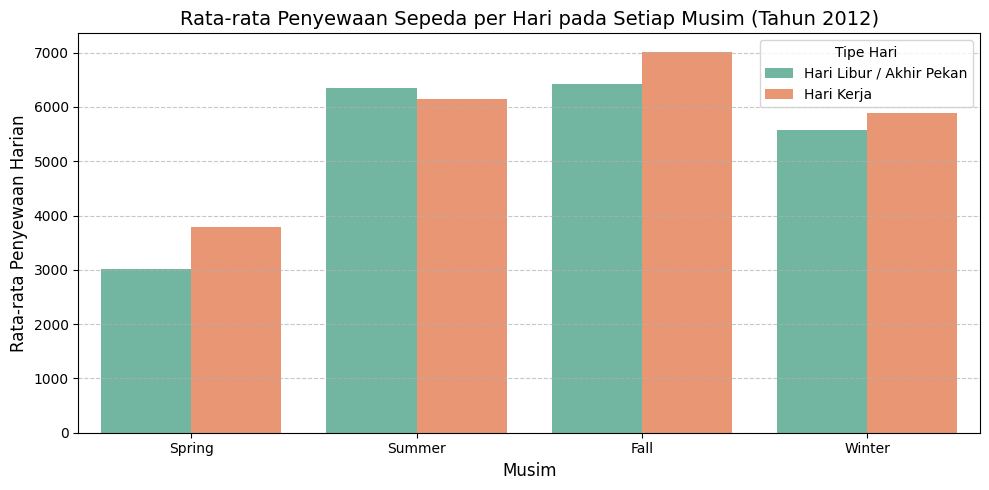

In [16]:
df_2012 = day_df[day_df['yr'] == 1]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_2012,
    x='season_label',
    y='cnt',
    hue='workingday_label',
    palette='Set2',
    errorbar=None
)
plt.title('Rata-rata Penyewaan Sepeda per Hari pada Setiap Musim (Tahun 2012)', fontsize=14)
plt.xlabel('Musim', fontsize=12)
plt.ylabel('Rata-rata Penyewaan Harian', fontsize=12)
plt.legend(title='Tipe Hari')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Conclusion & Recommendation

### Kesimpulan
1. **Pola Musim & Tipe Hari:** Volume penyewaan sepeda paling tinggi terjadi pada Musim Gugur (*Fall*) dan Musim Panas (*Summer*). Selain itu, penggunaan sepeda pada hari kerja selalu lebih tinggi dibanding hari libur di hampir semua musim. Hal ini mengindikasikan bahwa mayoritas pengguna memanfaatkan sepeda untuk moda transportasi komuter sehari-hari (berangkat kerja atau sekolah).
2. **Pengaruh Suhu Udara:** Permintaan penyewaan meningkat signifikan saat suhu udara berada di kategori *Sedang* hingga *Panas*. Sebaliknya, penyewaan menurun drastis pada kategori suhu *Dingin*, karena cuaca dingin cenderung mengurangi minat masyarakat beraktivitas di luar ruangan.

### Action Items / Rekomendasi
- **Penambahan Unit Armada:** Mengalokasikan lebih banyak unit sepeda di stasiun-stasiun sekitar kawasan perkantoran dan pusat transportasi umum pada hari kerja di Musim Panas dan Musim Gugur.
- **Jadwal Pemeliharaan Rutin (*Maintenance*):** Memanfaatkan Musim Dingin (periode dengan tingkat penyewaan paling rendah) untuk melakukan perbaikan dan perawatan besar-besaran pada armada sepeda agar kondisi unit optimal saat memasuki musim puncak.

## Menyiapkan Berkas Dashboard Streamlit

Membuat file `dashboard.py` secara otomatis di dalam direktori kerja Colab.

In [17]:
%%writefile dashboard.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(page_title="Bike Sharing Dashboard", page_icon="🚲", layout="wide")

@st.cache_data
def load_data():
    df = pd.read_csv("dashboard/main_data.csv")
    df['dteday'] = pd.to_datetime(df['dteday'])
    return df

df = load_data()

st.title("🚲 Bike Sharing Analytics Dashboard")
st.markdown("Dashboard interaktif untuk memantau performa dan pola penyewaan sepeda harian.")

# Sidebar Filter
st.sidebar.header("Filter Data")
year_option = st.sidebar.selectbox("Pilih Tahun:", options=["Semua Tahun", "2011", "2012"])
season_option = st.sidebar.multiselect("Pilih Musim:", options=df['season_label'].unique(), default=df['season_label'].unique())

filtered_df = df.copy()

if year_option == "2011":
    filtered_df = filtered_df[filtered_df['yr'] == 0]
elif year_option == "2012":
    filtered_df = filtered_df[filtered_df['yr'] == 1]

filtered_df = filtered_df[filtered_df['season_label'].isin(season_option)]

# Metrics
col1, col2, col3 = st.columns(3)
col1.metric("Total Penyewaan", f"{filtered_df['cnt'].sum():,}")
col2.metric("Rata-rata Penyewaan/Hari", f"{int(filtered_df['cnt'].mean()):,} unit")
col3.metric("Hari Terdaftar", f"{len(filtered_df)} hari")

st.divider()

# Charts
st.subheader("📊 Rata-rata Penyewaan Sepeda per Musim & Tipe Hari")
fig1, ax1 = plt.subplots(figsize=(10, 4))
sns.barplot(
    data=filtered_df,
    x='season_label',
    y='cnt',
    hue='workingday_label',
    palette='Set2',
    errorbar=None,
    ax=ax1
)
ax1.set_xlabel("Musim")
ax1.set_ylabel("Rata-rata Penyewaan Harian")
ax1.grid(axis='y', linestyle='--', alpha=0.5)
st.pyplot(fig1)

st.subheader("🌡️ Distribusi Penyewaan Berdasarkan Kategori Suhu")
bins = [0, 0.3, 0.6, 1.0]
labels = ['Dingin', 'Sedang', 'Panas']
filtered_df['temp_category'] = pd.cut(filtered_df['temp'], bins=bins, labels=labels)

fig2, ax2 = plt.subplots(figsize=(8, 4))
sns.boxplot(
    data=filtered_df,
    x='temp_category',
    y='cnt',
    palette='coolwarm',
    ax=ax2
)
ax2.set_xlabel("Kategori Suhu Udara")
ax2.set_ylabel("Total Penyewaan Harian")
ax2.grid(axis='y', linestyle='--', alpha=0.5)
st.pyplot(fig2)

Overwriting dashboard.py
